# Tutorial 3 OpenCV PnP


Load the required libraries

In [2]:
import cv2
import numpy as np
import math
import matplotlib.pyplot as plt
import sys

## Doing Calibration

The calibration process is required for ....

You must define:
1. Number of inner corners
1. square size in meters

How to do the calibration:
1. Run the code.
1. Put the image.
1. Capture the image using C couple of times.
1. Save the results using Q.

In [5]:

# Define Checkerboard Properties

# OpenCV counts INNER corners, not squares. A standard 10x7 square board has 9x6 inner corners.
CHESSBOARD_SIZE = (9, 6)

# Physical size of one printed square in meters (e.g., 25mm)
SQUARE_SIZE = 0.025

# 2. Prepare 3D Object Points
# Creates a grid of coordinates: (0,0,0), (1,0,0), (2,0,0) ... scaled by the physical square size
objp = np.zeros((CHESSBOARD_SIZE[0] * CHESSBOARD_SIZE[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:CHESSBOARD_SIZE[0], 0:CHESSBOARD_SIZE[1]].T.reshape(-1, 2)
objp *= SQUARE_SIZE

# Arrays to store object points (3D) and image points (2D) from all captured frames
objpoints = [] 
imgpoints = []

cap = cv2.VideoCapture(0)
print("--- CALIBRATION MODE ---")
print("Move the checkerboard around. Press 'c' to capture a frame. Press 'q' to compute calibration.")

captured_frames = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break
        
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    
    # Find the chessboard corners
    ret_board, corners = cv2.findChessboardCorners(gray, CHESSBOARD_SIZE, None)
    
    # If found, draw them on the live feed
    if ret_board:
        # Refine the corner coordinates to sub-pixel accuracy before drawing/saving
        criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
        corners_refined = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)
        
        cv2.drawChessboardCorners(frame, CHESSBOARD_SIZE, corners_refined, ret_board)
        
        # User input handling inside the detection block
        key = cv2.waitKey(1) & 0xFF
        if key == ord('c'):
            objpoints.append(objp)
            imgpoints.append(corners_refined)
            captured_frames += 1
            print(f"Captured frame {captured_frames}/15+")
    else:
        key = cv2.waitKey(1) & 0xFF
        
    # UI Text
    cv2.putText(frame, f"Captured: {captured_frames}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
    cv2.imshow('Camera Calibration', frame)
    
    if key == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

# ==========================================
# 3. COMPUTE THE CALIBRATION MATRICES
# ==========================================
if captured_frames > 0:
    print("\nCalculating intrinsic parameters... please wait.")
    # ret is the overall RMS re-projection error. mtx is the Camera Matrix. dist is the Distortion array.
    ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, gray.shape[::-1], None, None)
    
    print("\n--- CALIBRATION RESULTS ---")
    print(f"RMS Re-projection Error: {ret:.4f} pixels (Should ideally be < 1.0)")
    print("\nCamera Intrinsic Matrix (K):")
    print(np.round(mtx, 2))
    print("\nLens Distortion Coefficients:")
    print(np.round(dist, 4))
    
    # Save the calibration data to a NumPy archive file so the ArUco script can load it
    np.savez('webcam_calibration.npz', mtx=mtx, dist=dist)
    print("\nSaved parameters to 'webcam_calibration.npz'. You can now use these in your ArUco PnP script!")
else:
    print("Error: No frames were captured.")

--- CALIBRATION MODE ---
Move the checkerboard around. Press 'c' to capture a frame. Press 'q' to compute calibration.
Captured frame 1/15+
Captured frame 2/15+
Captured frame 3/15+
Captured frame 4/15+

Calculating intrinsic parameters... please wait.

--- CALIBRATION RESULTS ---
RMS Re-projection Error: 3.1420 pixels (Should ideally be < 1.0)

Camera Intrinsic Matrix (K):
[[1.19428e+03 0.00000e+00 2.66440e+02]
 [0.00000e+00 1.34176e+03 7.49430e+02]
 [0.00000e+00 0.00000e+00 1.00000e+00]]

Lens Distortion Coefficients:
[[-0.2652  1.6928  0.1158 -0.0438 -2.0443]]

Saved parameters to 'webcam_calibration.npz'. You can now use these in your ArUco PnP script!


## Detecting Aruco Tags

### Making The Tags
Now we can use check our calibrated camera using Aruco Tags.

We can use the code below to generate the tags.
See the line 
```
aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250)
```
remember the argument used.

After generating the tags we print the image (make sure to not scale it).

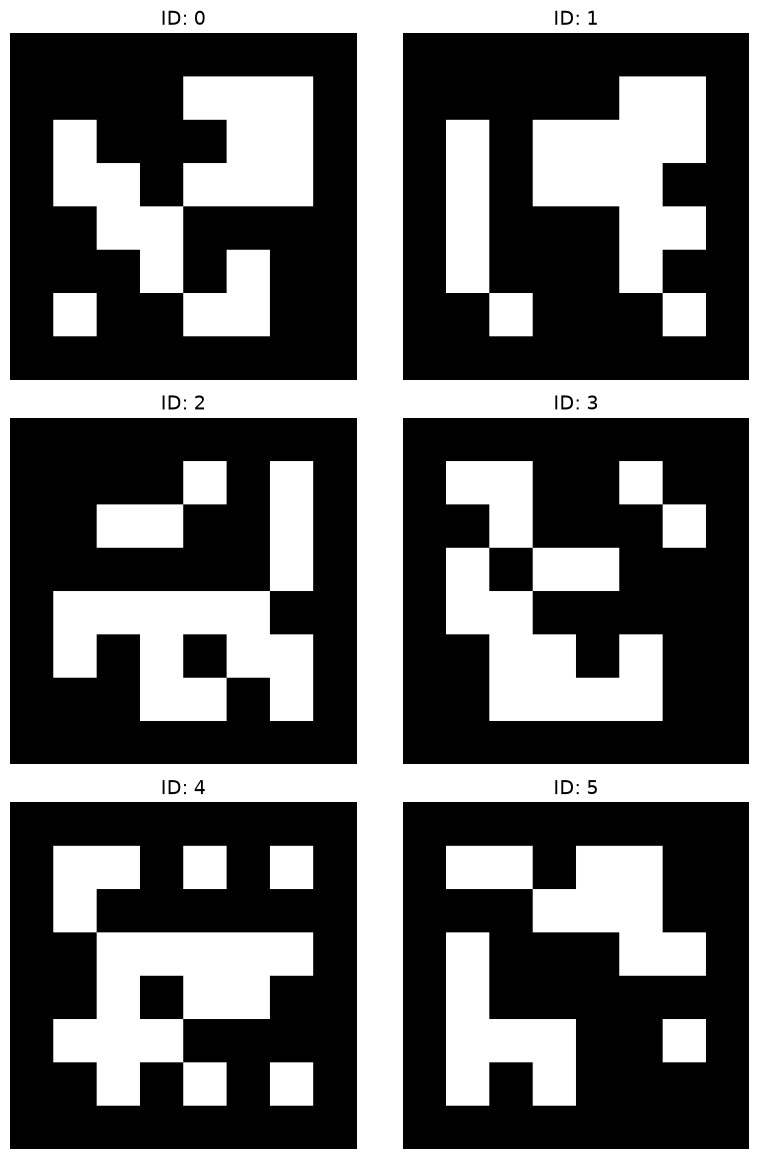

In [ ]:

# 1. Load the exact same dictionary used in the detection script
aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250)

# 2. Create an A4-proportioned figure for printing (8.27 x 11.69 inches)
plt.figure(figsize=(8.27, 11.69))

# 3. Generate 6 distinct markers (IDs 0 through 5)
for i in range(6):
    # generateImageMarker(dictionary, marker_id, side_pixels)
    # 400x400 pixels ensures the black and white edges are razor sharp
    marker_img = cv2.aruco.generateImageMarker(aruco_dict, id=i, sidePixels=400)
    
    # Arrange them in a 3-row, 2-column grid
    plt.subplot(3, 2, i + 1)
    plt.imshow(marker_img, cmap='gray')
    plt.title(f"ID: {i}", fontsize=14)
    plt.axis('off')

# 4. Save directly as a PDF ready for the lab printer
plt.tight_layout()
plt.savefig('printable_aruco_tags.pdf', dpi=300, bbox_inches='tight')
plt.show()

### Test Detect Aruco Tags

1. Define the marker size correctly from the printed image.
1. Load the calibration results we've made.
1. We must define the same

```
aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250)
```

In [6]:
# 1. Physical Payload Coordinates
# Make sure this matches your printed paper size! (0.05 = 5cm, 0.20 = 20cm)
marker_size = 0.05 
obj_pts = np.array([
    [-marker_size/2,  marker_size/2, 0],
    [ marker_size/2,  marker_size/2, 0],
    [ marker_size/2, -marker_size/2, 0],
    [-marker_size/2, -marker_size/2, 0]
], dtype=np.float32)

# CHANGE THESE NUMBER TO CALIBRATE 
# 
# focal_length = 600.0
# camera_matrix = np.array([
#     [focal_length, 0, 1280 / 2],
#     [0, focal_length, 720 / 2],
#     [0, 0, 1]
# ], dtype=np.float32)
# dist_coeffs = np.zeros((4, 1), dtype=np.float32)

# Load the Real Camera Calibration Data
try:
    with np.load('webcam_calibration.npz') as data:
        camera_matrix = data['mtx']
        dist_coeffs = data['dist']
    print("Successfully loaded camera calibration data.")
except IOError:
    print("Error: 'webcam_calibration.npz' not found. Please run the calibration script first!")
    sys.exit()

# 3. Setup ArUco Dictionary and Video Capture
aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250)
parameters = cv2.aruco.DetectorParameters()
detector = cv2.aruco.ArucoDetector(aruco_dict, parameters)

cap = cv2.VideoCapture(0)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

print("Starting video feed. Press 'q' to exit.")

while True:
    ret, frame = cap.read()
    if not ret:
        break
        
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    
    # Detect all markers in the current frame
    corners, ids, rejected = detector.detectMarkers(gray)
    
    if ids is not None:
        # Draw the green bounding box around ALL detected markers
        cv2.aruco.drawDetectedMarkers(frame, corners, ids)
        
        # Loop through every marker detected in this frame
        for i in range(len(ids)):
            img_pts = corners[i][0]
            # marker_id = ids[i][0]
            
            # Solve PnP for this specific marker
            success, rvec, tvec = cv2.solvePnP(obj_pts, img_pts, camera_matrix, dist_coeffs, flags=cv2.SOLVEPNP_ITERATIVE)
            
            if success:
                # Use OpenCV's built-in axis drawing tool (cleaner than manual line projection)
                # The 0.03 is the length of the drawn axes in meters
                cv2.drawFrameAxes(frame, camera_matrix, dist_coeffs, rvec, tvec, 0.03)
                
                # Find the center of the marker to position the text
                origin = tuple(np.int32(img_pts.mean(axis=0)))
                text_x = origin[0] - 50
                text_y = origin[1] - 40
                
                # Print the ID and translation (distance) floating above the marker
                text = f"X:{tvec[0][0]:.2f} Y:{tvec[1][0]:.2f} Z:{tvec[2][0]:.2f}"
                cv2.putText(frame, text, (text_x, text_y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 2)

    cv2.imshow('Multi-Agent Payload Tracking', frame)
    
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

Successfully loaded camera calibration data.
Starting video feed. Press 'q' to exit.


## Showing OOOIIAAA Cat

In [3]:
# 1. Load the Oia Cat image
cat_img = cv2.imread('oia_black.jpg')
cat_h, cat_w = cat_img.shape[:2]

# Define the 4 corners of the source image to be warped
cat_corners = np.array([
    [0, 0], [cat_w, 0], [cat_w, cat_h], [0, cat_h]
], dtype=np.float32)

# Size of the floating cat projection in meters (e.g., 10cm)
cat_size = 0.10  
spin_angle = 0.0

# 1. Physical Payload Coordinates
# Make sure this matches your printed paper size! (0.05 = 5cm, 0.20 = 20cm)
marker_size = 0.05 
obj_pts = np.array([
    [-marker_size/2,  marker_size/2, 0],
    [ marker_size/2,  marker_size/2, 0],
    [ marker_size/2, -marker_size/2, 0],
    [-marker_size/2, -marker_size/2, 0]
], dtype=np.float32)

# CHANGE THESE NUMBER TO CALIBRATE 
# 
focal_length = 600.0
camera_matrix = np.array([
    [focal_length, 0, 1280 / 2],
    [0, focal_length, 720 / 2],
    [0, 0, 1]
], dtype=np.float32)
dist_coeffs = np.zeros((4, 1), dtype=np.float32)

# 3. Setup ArUco Dictionary and Video Capture
aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250)
parameters = cv2.aruco.DetectorParameters()
detector = cv2.aruco.ArucoDetector(aruco_dict, parameters)

cap = cv2.VideoCapture(0)

cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

print("Starting video feed. Press 'q' to exit.")

while True:
    ret, frame = cap.read()
    if not ret: break
        
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    corners, ids, rejected = detector.detectMarkers(gray)
    
    if ids is not None:
        # Increase the angle every frame to make it spin
        spin_angle += 5.0 
        theta = math.radians(spin_angle)
        
        # Pre-calculate sine and cosine for the Z-axis rotation matrix
        cos_t = math.cos(theta)
        sin_t = math.sin(theta)
        
        for i in range(len(ids)):
            img_pts = corners[i][0]
            success, rvec, tvec = cv2.solvePnP(obj_pts, img_pts, camera_matrix, dist_coeffs, flags=cv2.SOLVEPNP_ITERATIVE)
            
            if success:
                # 2. Define a 3D square floating just above the marker
                # Z is negative because OpenCV's camera Z-axis points away from the camera
                pts_3d = np.array([
                    [-cat_size,  cat_size, 0],  # Top-Left
                    [ cat_size,  cat_size, 0],  # Top-Right
                    [ cat_size, -cat_size, 0],  # Bottom-Right
                    [-cat_size, -cat_size, 0]   # Bottom-Left
                ])
                
                # 3. Apply the Z-axis rotation matrix to the 3D points
                rotated_3d = np.zeros_like(pts_3d)
                for j in range(4):
                    x, y, z = pts_3d[j]
                    rotated_3d[j][0] = x * cos_t - y * sin_t
                    rotated_3d[j][1] = x * sin_t + y * cos_t
                    rotated_3d[j][2] = z
                
                # 4. Project the spinning 3D points down to 2D image pixels
                img_pts_2d, _ = cv2.projectPoints(rotated_3d, rvec, tvec, camera_matrix, dist_coeffs)
                img_pts_2d = img_pts_2d.reshape(-1, 2)
                
                # 5. Calculate Homography and Warp the Cat Image
                H, _ = cv2.findHomography(cat_corners, img_pts_2d)
                warped_cat = cv2.warpPerspective(cat_img, H, (frame.shape[1], frame.shape[0]))
                
                # 6. Masking (Overlay the cat onto the frame without the black background)
                mask = cv2.cvtColor(warped_cat, cv2.COLOR_BGR2GRAY)
                _, mask = cv2.threshold(mask, 1, 255, cv2.THRESH_BINARY)
                mask_inv = cv2.bitwise_not(mask)
                
                frame_bg = cv2.bitwise_and(frame, frame, mask=mask_inv)
                frame = cv2.add(frame_bg, warped_cat)

    cv2.imshow('Oia Cat AR Tracking', frame)
    if cv2.waitKey(1) & 0xFF == ord('q'): break

cap.release()
cv2.destroyAllWindows()

Starting video feed. Press 'q' to exit.
